## Step 1: Import the required libraries

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load and preprocess the dataset

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Original training images:", x_train.shape)
print("Original testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training images: (60000, 28, 28)
Original testing images: (10000, 28, 28)


### Normalize pixel values
Convert pixel values from the range 0–255 to the range 0–1.

In [3]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

### Select normal and anomalous data
Train the Autoencoder only on digit 0 images. For testing, retain digit 0 (normal) and digit 1 (anomalous).

In [4]:
# Train only on normal images (digit 0)
x_train = x_train[y_train == 0]

# Prepare test images of digit 0 and digit 1
test_mask = np.isin(y_test, [0, 1])
x_test = x_test[test_mask]
y_test = y_test[test_mask]

print("Normal training images:", x_train.shape)
print("Test images (digits 0 and 1):", x_test.shape)
print("Test labels:", y_test.shape)

Normal training images: (5923, 28, 28)
Test images (digits 0 and 1): (2115, 28, 28)
Test labels: (2115,)


## Step 3: Flatten the images
Each 28 × 28 image is converted into a vector containing 784 pixel values.

In [5]:
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Flattened training shape:", x_train.shape)
print("Flattened testing shape:", x_test.shape)

Flattened training shape: (5923, 784)
Flattened testing shape: (2115, 784)


## Step 4: Build the Autoencoder
The encoder compresses 784 input values into 32 features. The decoder reconstructs the 784 output values.

In [6]:
input_layer = keras.Input(shape=(784,))

# Encoder
encoded = layers.Dense(128, activation="relu")(input_layer)
encoded = layers.Dense(32, activation="relu")(encoded)

# Decoder
decoded = layers.Dense(128, activation="relu")(encoded)
output_layer = layers.Dense(784, activation="sigmoid")(decoded)

autoencoder = keras.Model(input_layer, output_layer)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Compile the model

In [7]:
autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

## Step 6: Train the Autoencoder
The input and target are both `x_train` because an Autoencoder learns to reconstruct its own input.

In [8]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.1052 - mae: 0.2310 - val_loss: 0.0558 - val_mae: 0.1214
Epoch 2/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0493 - mae: 0.1118 - val_loss: 0.0403 - val_mae: 0.0977
Epoch 3/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0373 - mae: 0.0914 - val_loss: 0.0331 - val_mae: 0.0840
Epoch 4/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0320 - mae: 0.0824 - val_loss: 0.0287 - val_mae: 0.0768
Epoch 5/5
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0278 - mae: 0.0748 - val_loss: 0.0254 - val_mae: 0.0699


## Step 7: Calculate reconstruction error
The reconstruction error is the mean squared difference between each original test image and its reconstructed version.

In [9]:
reconstructed = autoencoder.predict(x_test)

error = np.mean((x_test - reconstructed) ** 2, axis=1)

# Set threshold using the 95th percentile of normal (digit 0) test errors
threshold = np.percentile(error[y_test == 0], 95)

print("Anomaly threshold:", threshold)

67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Anomaly threshold: 0.04756129


## Step 8: Detect anomalies
An image is flagged as an anomaly when its reconstruction error is greater than the threshold.

In [10]:
predictions = error > threshold

for i in range(min(10, len(predictions))):
    if predictions[i]:
        print("Image", i, "- Anomaly")
    else:
        print("Image", i, "- Normal")

Image 0 - Anomaly
Image 1 - Normal
Image 2 - Anomaly
Image 3 - Normal
Image 4 - Normal
Image 5 - Anomaly
Image 6 - Normal
Image 7 - Normal
Image 8 - Anomaly
Image 9 - Anomaly


## Step 9: Display original and reconstructed images

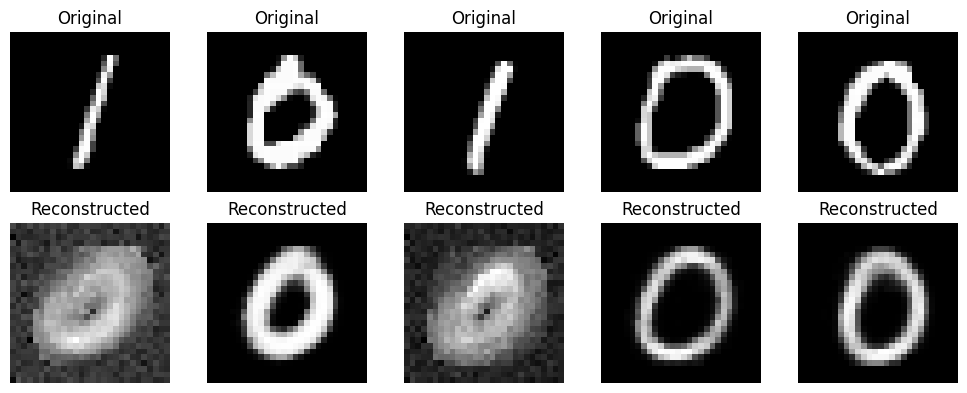

In [11]:
plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i + 6)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Result
An Autoencoder was implemented using TensorFlow and Keras. It was trained using normal MNIST digit 0 images. Reconstruction errors were calculated for test images containing digits 0 and 1, and images with errors above the selected threshold were identified as potential anomalies. Original and reconstructed images were displayed.

# Viva-Voce Preparation: Theory and Questions with Answers

## A. Autoencoder fundamentals

**1. What is an Autoencoder?**  
An Autoencoder is a type of neural network that learns to reproduce its input at its output. It learns a compressed representation of the input and then reconstructs the original data.

**2. What are the main parts of an Autoencoder?**  
The two main parts are the encoder and the decoder. The encoder compresses the input into a smaller representation, and the decoder reconstructs the input from that representation.

**3. What is the encoder?**  
The encoder is the part of the Autoencoder that converts the input into a compact representation called the latent representation or encoded representation.

**4. What is the decoder?**  
The decoder takes the encoded representation and attempts to reconstruct the original input.

**5. What is a latent representation?**  
It is the compressed set of features learned by the encoder. In this practical, the encoder reduces 784 input values to 32 features.

**6. Why is an Autoencoder called an unsupervised learning model?**  
It can learn from input data without requiring a separate class label as the reconstruction target. It uses the input itself as the target. This practical uses digit labels to select normal and test examples, but the Autoencoder is trained to reconstruct images.

**7. What is reconstruction?**  
Reconstruction is the output produced by the decoder to approximate the original input image.

## B. Anomaly detection

**8. What is anomaly detection?**  
Anomaly detection is the process of identifying data points that differ significantly from normal or expected data.

**9. How does an Autoencoder perform anomaly detection?**  
It is trained mainly on normal examples. It generally reconstructs similar normal examples with lower error. Unusual examples may have higher reconstruction error and can be flagged as anomalies.

**10. Which dataset is used in this practical?**  
The MNIST handwritten digit dataset.

**11. Which digit is considered normal?**  
Digit 0 is considered normal data.

**12. Which digit is considered anomalous?**  
Digit 1 is considered anomalous data.

**13. Why is the Autoencoder trained only on digit 0?**  
It learns the reconstruction patterns of the selected normal class. Digit 1 is not included in training, so its reconstruction error can be compared with the normal-data threshold.

**14. Does the Autoencoder use digit labels as its training target?**  
No. It uses `x_train` as both input and target. Labels are used to select digit 0 for training and digits 0 and 1 for testing and threshold calculation.

**15. What is reconstruction error?**  
It is a numerical measure of the difference between an original input and its reconstructed output. A larger error indicates a less accurate reconstruction.

**16. How is an anomaly identified in this practical?**  
If an image's reconstruction error is greater than the threshold, it is classified as a potential anomaly. Otherwise, it is classified as normal.

**17. What is an anomaly threshold?**  
It is a cutoff value used to separate normal-looking reconstruction errors from errors considered unusually high.

**18. How is the threshold selected in this practical?**  
It is set to the 95th percentile of reconstruction errors for test images whose label is 0.

**19. What does the 95th percentile mean here?**  
It is a value at or below which approximately 95% of the normal test reconstruction errors fall. Errors above it are flagged by the rule used in this practical.

**20. Is the threshold guaranteed to detect every anomaly correctly?**  
No. It is a chosen cutoff. Some normal images may exceed it, and some anomalous images may fall below it.

## C. Architecture and activation functions

**21. What is the input size of the Autoencoder?**  
The input size is 784 because each 28 × 28 image is flattened into 784 values.

**22. Why are MNIST images flattened?**  
The Autoencoder in this practical uses Dense layers, which receive one-dimensional feature vectors. Flattening converts each 28 × 28 image into a vector of length 784.

**23. What does `Dense(128, activation="relu")` do?**  
It creates a fully connected layer with 128 neurons and ReLU activation.

**24. What does the 32-neuron encoder layer do?**  
It creates a compact encoded representation of the input with 32 features.

**25. Why does the decoder use 128 neurons?**  
It expands the 32-feature encoded representation into a larger representation before producing the reconstructed 784 values.

**26. Why does the output layer have 784 neurons?**  
The output must have the same number of values as the flattened input so the reconstructed image can be compared with the original.

**27. Why is ReLU used in the hidden layers?**  
ReLU introduces non-linearity and returns `max(0, x)`, allowing the network to learn more complex relationships.

**28. Why is sigmoid used in the output layer?**  
Sigmoid produces output values between 0 and 1, matching the normalized pixel-value range used in this practical.

**29. What is the difference between an encoder and a decoder?**  
The encoder compresses input information into a smaller representation. The decoder uses that representation to reconstruct the input.

## D. Training and loss functions

**30. Which optimizer is used?**  
Adam.

**31. What is Adam?**  
Adam is an adaptive optimization algorithm that uses estimates of the gradients and their moments to update model weights.

**32. What is MSE?**  
Mean Squared Error is the average of squared differences between actual and reconstructed values. It is used as the loss function in this practical.

**33. What is the formula for MSE?**  
For N values, `MSE = (1/N) × Σ(actual − predicted)²`.

**34. What is MAE?**  
Mean Absolute Error is the average absolute difference between actual and reconstructed values. It is included as a metric in this practical.

**35. What is the difference between MSE and MAE?**  
MSE squares the differences, so larger errors receive more weight. MAE takes absolute differences and is less influenced by large individual errors.

**36. Why are input and target both `x_train` in `fit()`?**  
Because the Autoencoder is trained to reproduce its own input. It learns to map an image to a reconstruction of that same image.

**37. What is an epoch?**  
One complete pass through the training dataset. This practical uses 5 epochs.

**38. What is batch size?**  
The number of training examples processed before an optimizer update. This practical uses 128.

**39. What does `validation_split=0.1` mean?**  
It reserves 10% of the supplied training data for validation and uses the remaining 90% for training.

## E. Dataset and preprocessing

**40. What is MNIST?**  
A dataset of handwritten digits 0–9. It contains 60,000 training images and 10,000 testing images, each 28 × 28 pixels.

**41. Why normalize pixel values?**  
Dividing pixel values by 255 converts them from 0–255 to 0–1, which is suitable for the sigmoid output and can help training.

**42. What does `astype("float32")` do?**  
It converts the image data to 32-bit floating-point values.

**43. What does `y_train == 0` do?**  
It creates a Boolean mask that is true for training labels equal to zero. Applying it to `x_train` selects only digit 0 images.

**44. What does `np.isin(y_test, [0, 1])` do?**  
It returns a Boolean mask identifying labels that are either 0 or 1.

**45. What does `reshape(-1, 784)` do?**  
It reshapes the images into rows of 784 values. The `-1` tells NumPy to infer the number of rows automatically.

## F. Code and result

**46. What does `keras.Input(shape=(784,))` define?**  
It defines the input of the model as a vector containing 784 values.

**47. What does `keras.Model(input_layer, output_layer)` do?**  
It creates a Keras model that maps the specified input tensor to the specified output tensor.

**48. What does `autoencoder.predict(x_test)` return?**  
It returns reconstructed versions of the test images.

**49. What does `np.mean((x_test - reconstructed) ** 2, axis=1)` calculate?**  
It calculates one mean squared reconstruction error for each test image by averaging over its 784 pixel values.

**50. Why display original and reconstructed images?**  
To visually compare the input images with the Autoencoder's reconstructions and understand how well the model reproduces them.

**51. What does `plt.imshow()` do?**  
It displays image data as an image. The `cmap="gray"` argument displays it using grayscale shades.

**52. What are possible applications of Autoencoders?**  
Anomaly detection, data compression, denoising, feature learning, and image reconstruction.

**53. What is a limitation of this practical's approach?**  
It treats digit 0 as normal and digit 1 as anomalous, so the result is specific to this chosen setup. The threshold is also estimated from normal test examples in this demonstration.

## Important values to remember

| Item | Value |
|---|---|
| Dataset | MNIST |
| Normal class | Digit 0 |
| Anomalous class | Digit 1 |
| Original image size | 28 × 28 |
| Flattened input size | 784 |
| Encoder layers | 128, then 32 neurons |
| Decoder hidden layer | 128 neurons |
| Output size | 784 |
| Hidden activation | ReLU |
| Output activation | Sigmoid |
| Optimizer | Adam |
| Loss | MSE |
| Metric | MAE |
| Epochs | 5 |
| Batch size | 128 |
| Validation split | 0.1 (10%) |
| Threshold | 95th percentile of digit 0 test errors |

**Source note:** The notebook follows the uploaded practical's method and values. The supplied practical uses digit 0 as normal, digit 1 as anomalous, and calculates the threshold from digit 0 test reconstruction errors. This is a demonstration setup, not a general-purpose anomaly-detection benchmark.